In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("train.csv")

print("Shape:", df.shape)
display(df.head())
df.info()

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({"Missing Count": missing, "Percentage (%)": missing_pct.round(2)})
display(missing_df)
print(f"Total columns with missing values: {len(missing_df)}")

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,Missing Count,Percentage (%)
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


Total columns with missing values: 19


In [29]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"],
}

for col, order in ordinal_map.items():
    df[col] = pd.Categorical(df[col], categories=order, ordered=True)

summary_rows = []
for col in df.columns:
    if col in ordinal_map or col == "OverallQual":
        vtype = "Ordinal"
    elif col in numeric_cols:
        vtype = "Numerical"
    else:
        vtype = "Categorical"
    examples = df[col].dropna().unique()[:3].tolist()
    summary_rows.append({
        "Column": col,
        "Type": vtype,
        "Unique Values": df[col].nunique(),
        "Examples": examples
    })

summary_table = pd.DataFrame(summary_rows)
display(summary_table)

,Column,Type,Unique Values,Examples
0,Id,Numerical,1460,"[1, 2, 3]"
1,MSSubClass,Numerical,15,"[60, 20, 70]"
2,MSZoning,Categorical,5,"[RL, RM, C (all)]"
3,LotFrontage,Numerical,110,"[65.0, 80.0, 68.0]"
4,LotArea,Numerical,1073,"[8450, 9600, 11250]"
...,...,...,...,...
76,MoSold,Numerical,12,"[2, 5, 9]"
77,YrSold,Numerical,5,"[2008, 2007, 2006]"
78,SaleType,Categorical,9,"[WD, New, COD]"
79,SaleCondition,Categorical,6,"[Normal, Abnorml, Partial]"


In [30]:
display(df[numeric_cols].describe().T)

for col in ["SalePrice", "GrLivArea", "LotArea"]:
    s = df[col].dropna()
    mean_val = s.mean()
    median_val = s.median()
    mode_val = s.mode()[0]
    std_val = s.std()
    var_val = s.var()
    range_val = s.max() - s.min()
    iqr_val = s.quantile(0.75) - s.quantile(0.25)
    skew_val = stats.skew(s)
    kurt_val = stats.kurtosis(s)
    skew_dir = "right skewed" if mean_val > median_val else ("left skewed" if mean_val < median_val else "symmetric")

    print(f"\n--- {col} ---")
    print(f"Mean: {mean_val:,.2f} | Median: {median_val:,.2f} | Mode: {mode_val:,.2f}")
    print(f"Std: {std_val:,.2f} | Var: {var_val:,.2f} | Range: {range_val:,.2f} | IQR: {iqr_val:,.2f}")
    print(f"Skewness: {skew_val:.3f} ({skew_dir}) | Kurtosis: {kurt_val:.3f}")

for col in ["Neighborhood", "HouseStyle"]:
    print(f"\n--- {col} Value Counts ---")
    print(df[col].value_counts())
    print(f"Mode: {df[col].mode()[0]}")

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0



--- SalePrice ---
Mean: 180,921.20 | Median: 163,000.00 | Mode: 140,000.00
Std: 79,442.50 | Var: 6,311,111,264.30 | Range: 720,100.00 | IQR: 84,025.00
Skewness: 1.881 (right skewed) | Kurtosis: 6.510

--- GrLivArea ---
Mean: 1,515.46 | Median: 1,464.00 | Mode: 864.00
Std: 525.48 | Var: 276,129.63 | Range: 5,308.00 | IQR: 647.25
Skewness: 1.365 (right skewed) | Kurtosis: 4.874

--- LotArea ---
Mean: 10,516.83 | Median: 9,478.50 | Mode: 7,200.00
Std: 9,981.26 | Var: 99,625,649.65 | Range: 213,945.00 | IQR: 4,048.00
Skewness: 12.195 (right skewed) | Kurtosis: 202.544

--- Neighborhood Value Counts ---
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name:

In [31]:
df_raw = df.copy()

dup_count = df.duplicated().sum()
print("Duplicate rows:", dup_count)
if dup_count > 0:
    df = df.drop_duplicates()
    print("New shape:", df.shape)

obj_cols = df.select_dtypes(include=["object"]).columns
for col in obj_cols:
    vals = df[col].dropna().unique()
    cleaned = pd.Series(vals).astype(str).str.strip().str.lower()
    if cleaned.nunique() < len(vals):
        print(f"Inconsistent casing/spaces in {col}: {vals}")

absent_cols = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "MasVnrType"
]
for col in absent_cols:
    if col in df.columns:
        df[col] = df[col].fillna("None")

df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.median())
)
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())

for col in df.select_dtypes(include=[np.number]).columns:
    if df[col].isnull().sum() > 0:
        if col == "GarageYrBlt":
            df[col] = df[col].fillna(0)
        else:
            df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=["object", "category"]).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining missing values:", df.isnull().sum().sum())

print("YearBuilt > YrSold:", (df["YearBuilt"] > df["YrSold"]).sum())
area_cols = ["LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea"]
for col in area_cols:
    print(f"Negative {col}:", (df[col] < 0).sum())

Duplicate rows: 0
Remaining missing values: 0
YearBuilt > YrSold: 0
Negative LotArea: 0
Negative GrLivArea: 0
Negative TotalBsmtSF: 0
Negative GarageArea: 0


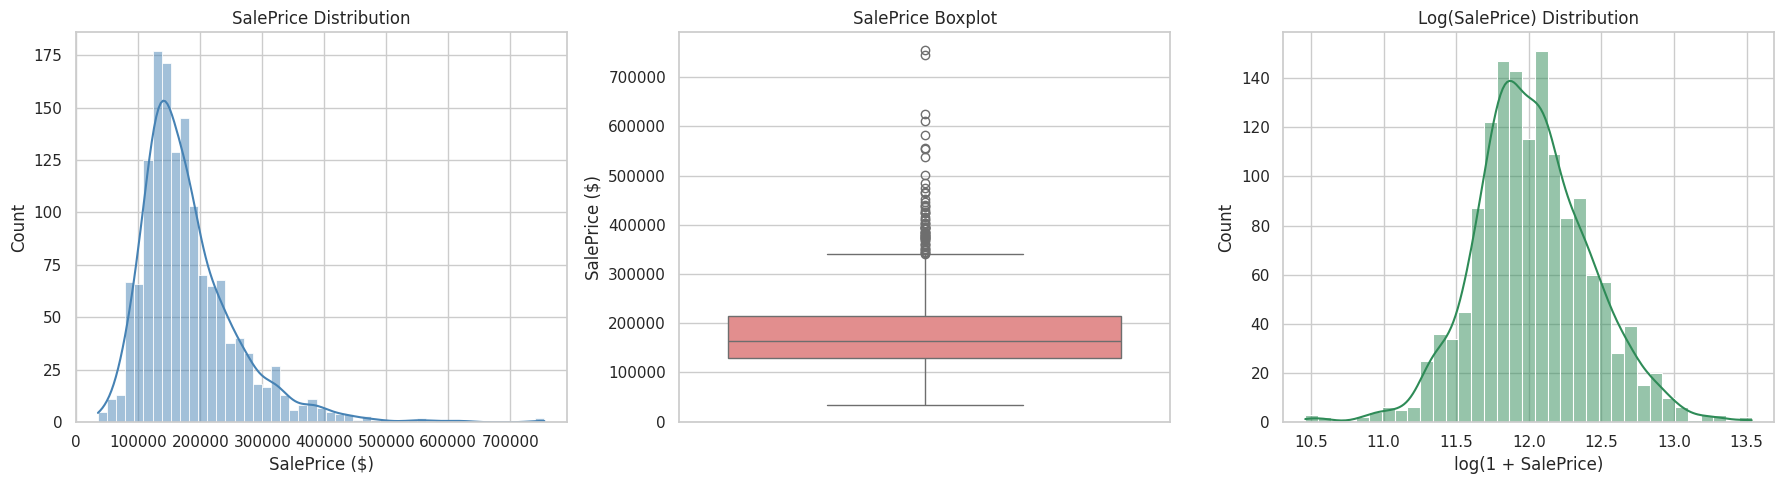

Skewness before log: 1.881
Skewness after log:  0.121


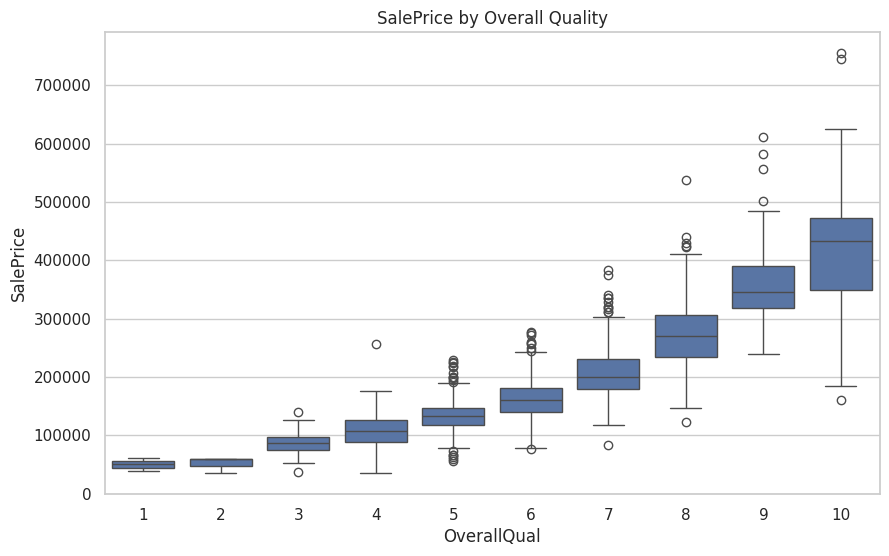

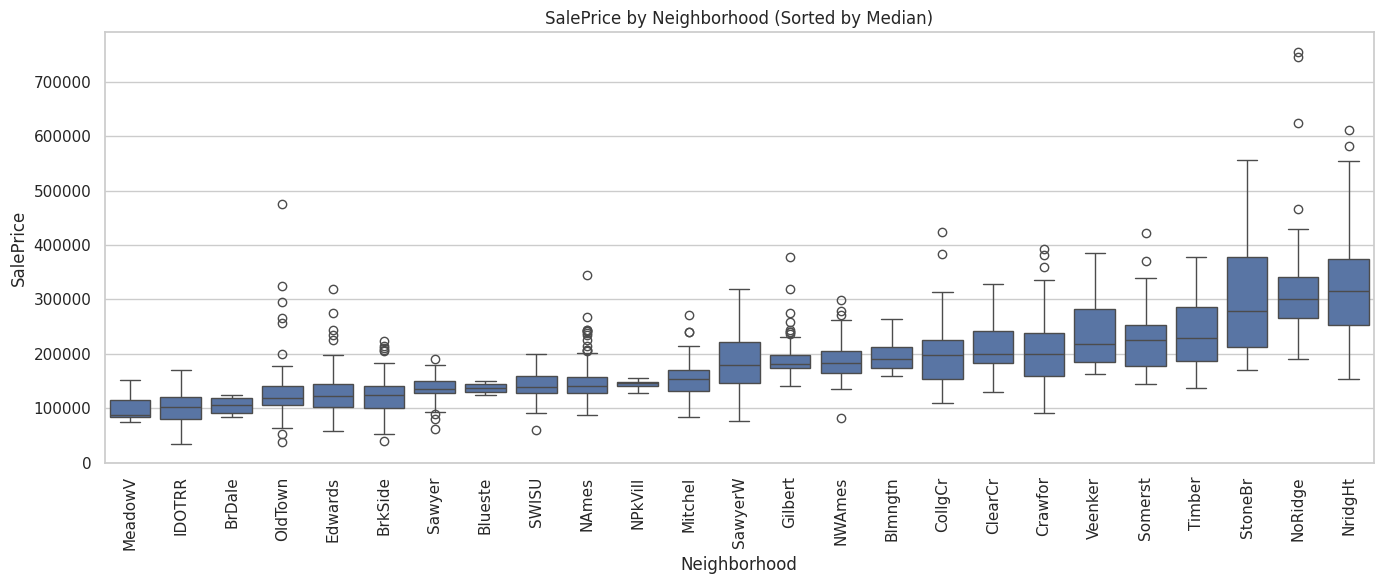

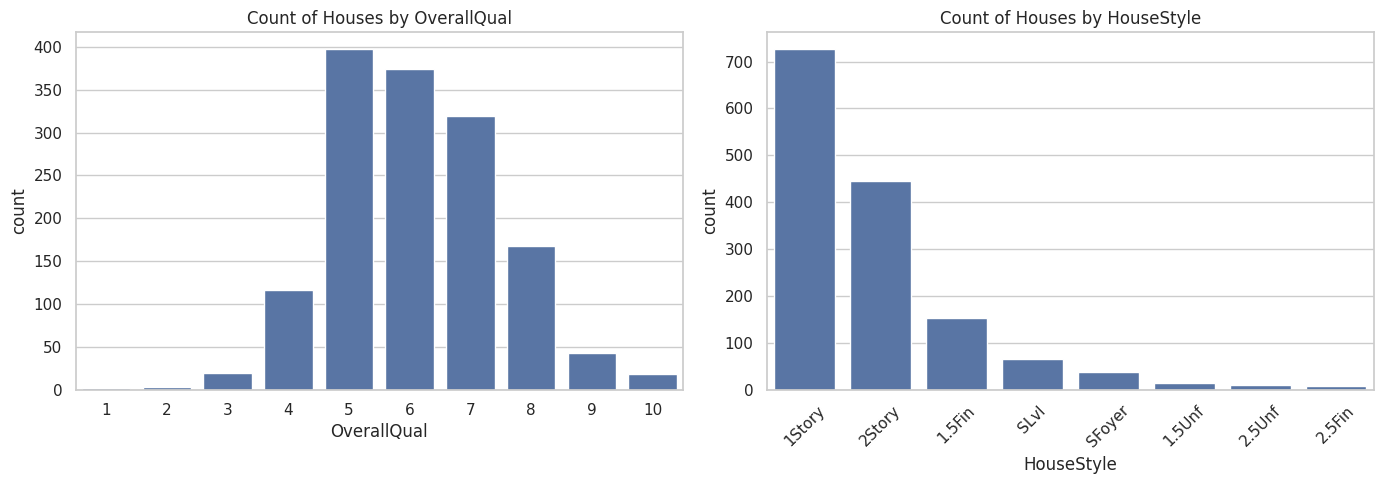

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("SalePrice ($)")
axes[0].set_ylabel("Count")

sns.boxplot(y=df["SalePrice"], ax=axes[1], color="lightcoral")
axes[1].set_title("SalePrice Boxplot")
axes[1].set_ylabel("SalePrice ($)")

log_price = np.log1p(df["SalePrice"])
sns.histplot(log_price, kde=True, ax=axes[2], color="seagreen")
axes[2].set_title("Log(SalePrice) Distribution")
axes[2].set_xlabel("log(1 + SalePrice)")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

print(f"Skewness before log: {stats.skew(df['SalePrice']):.3f}")
print(f"Skewness after log:  {stats.skew(log_price):.3f}")

plt.figure(figsize=(10, 6))
sns.boxplot(x="OverallQual", y="SalePrice", data=df)
plt.title("SalePrice by Overall Quality")
plt.show()

order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(14, 6))
sns.boxplot(x="Neighborhood", y="SalePrice", data=df, order=order)
plt.xticks(rotation=90)
plt.title("SalePrice by Neighborhood (Sorted by Median)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x="OverallQual", data=df, ax=axes[0])
axes[0].set_title("Count of Houses by OverallQual")
sns.countplot(x="HouseStyle", data=df, ax=axes[1], order=df["HouseStyle"].value_counts().index)
axes[1].set_title("Count of Houses by HouseStyle")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [33]:
num_df = df.select_dtypes(include=[np.number])
cov_matrix = num_df.cov()
corr_matrix = num_df.corr(method="pearson")

top_corr = corr_matrix["SalePrice"].abs().sort_values(ascending=False)
print("Top 10 features correlated with SalePrice (absolute Pearson r):")
print(corr_matrix.loc[top_corr.index[:11], "SalePrice"])

print("\nTop 3 Features (Covariance vs Correlation):")
for feat in top_corr.index[1:4]:
    print(f"{feat}: Cov = {cov_matrix.loc[feat, 'SalePrice']:,.2f} | Corr = {corr_matrix.loc[feat, 'SalePrice']:.3f}")

ordinal_numeric = df[["OverallQual", "SalePrice"]].corr(method="spearman")
print("\nSpearman correlation (OverallQual vs SalePrice):\n", ordinal_numeric)

Top 10 features correlated with SalePrice (absolute Pearson r):
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

Top 3 Features (Covariance vs Correlation):
OverallQual: Cov = 86,904.13 | Corr = 0.791
GrLivArea: Cov = 29,581,866.74 | Corr = 0.709
GarageCars: Cov = 38,020.18 | Corr = 0.640

Spearman correlation (OverallQual vs SalePrice):
              OverallQual  SalePrice
OverallQual     1.000000   0.809829
SalePrice       0.809829   1.000000


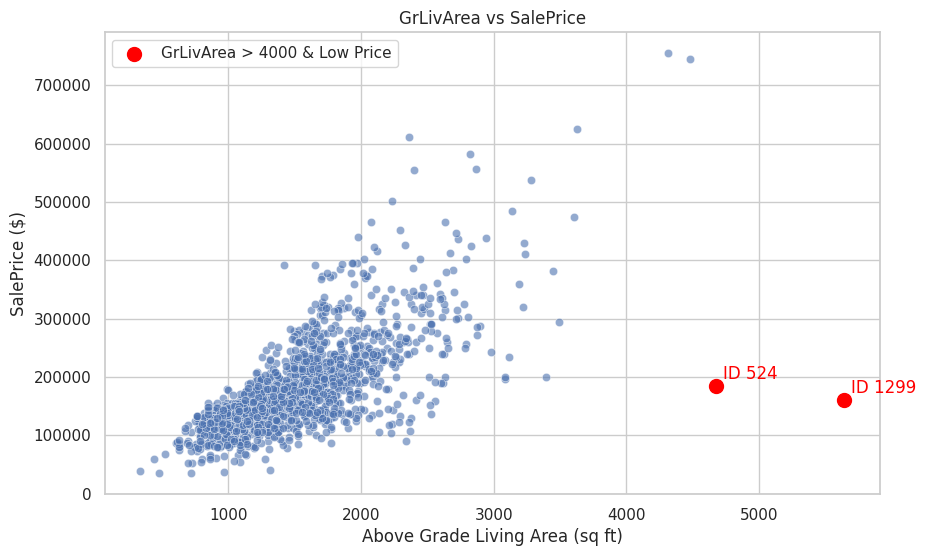

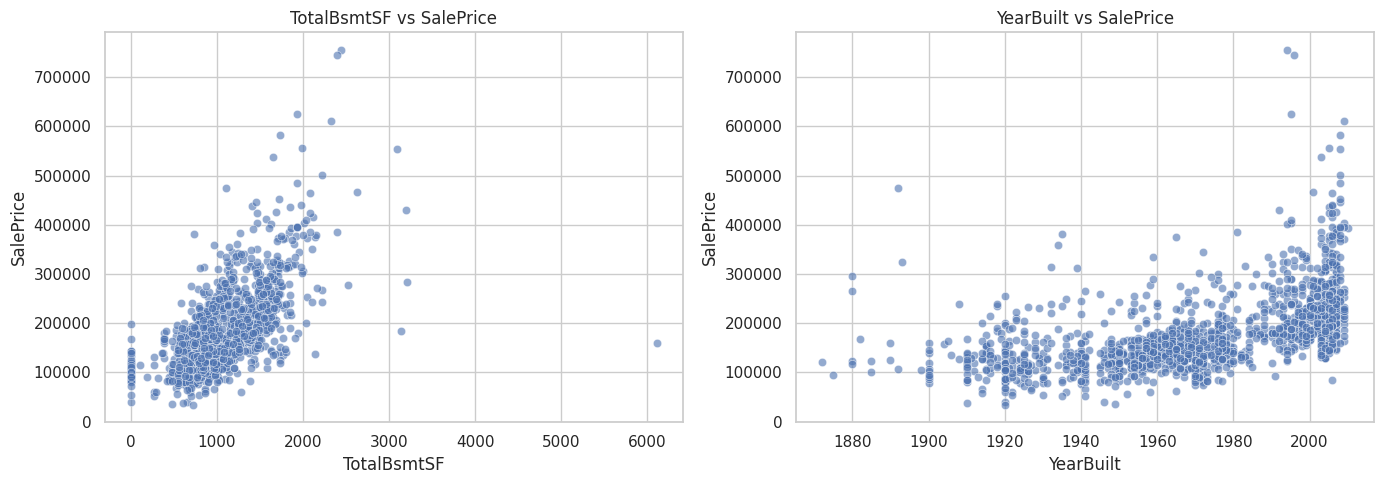

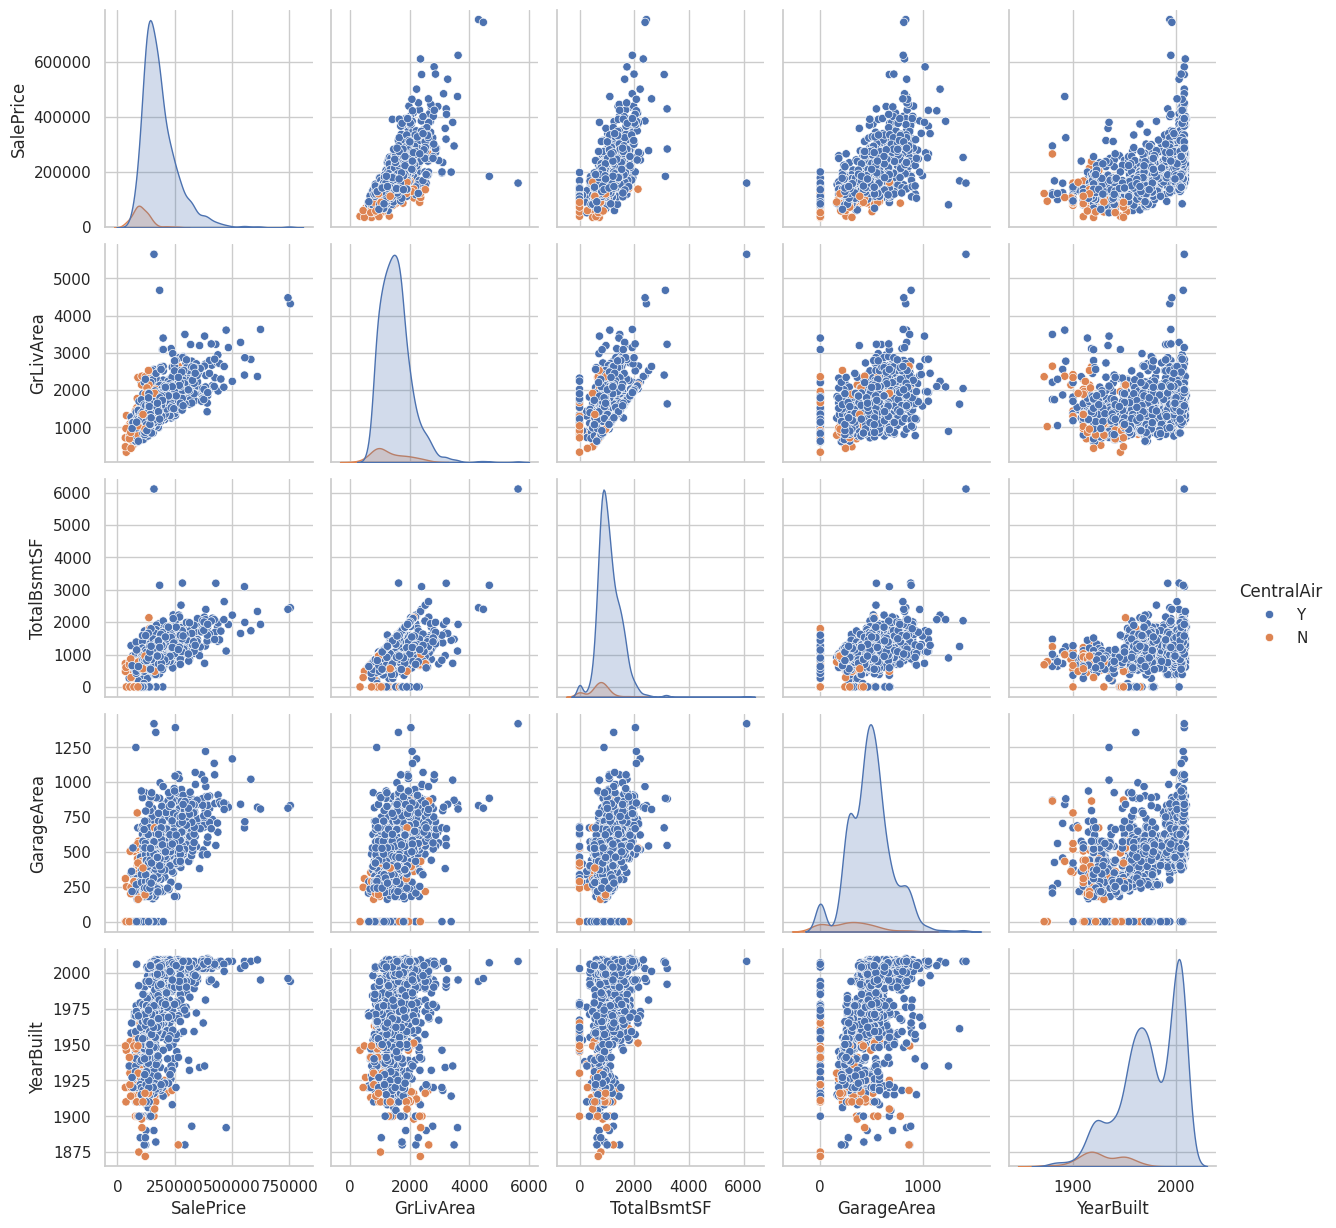

In [34]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df, alpha=0.6)
outliers_gl = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
plt.scatter(outliers_gl["GrLivArea"], outliers_gl["SalePrice"], color="red", s=100, label="GrLivArea > 4000 & Low Price")
for idx, row in outliers_gl.iterrows():
    plt.annotate(f"ID {row['Id']}", (row["GrLivArea"], row["SalePrice"]), xytext=(5, 5), textcoords="offset points", color="red")
plt.title("GrLivArea vs SalePrice")
plt.xlabel("Above Grade Living Area (sq ft)")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x="TotalBsmtSF", y="SalePrice", data=df, alpha=0.6, ax=axes[0])
axes[0].set_title("TotalBsmtSF vs SalePrice")
sns.scatterplot(x="YearBuilt", y="SalePrice", data=df, alpha=0.6, ax=axes[1])
axes[1].set_title("YearBuilt vs SalePrice")
plt.tight_layout()
plt.show()

selected = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt", "CentralAir"]
sns.pairplot(df[selected], hue="CentralAir", diag_kind="kde")
plt.show()

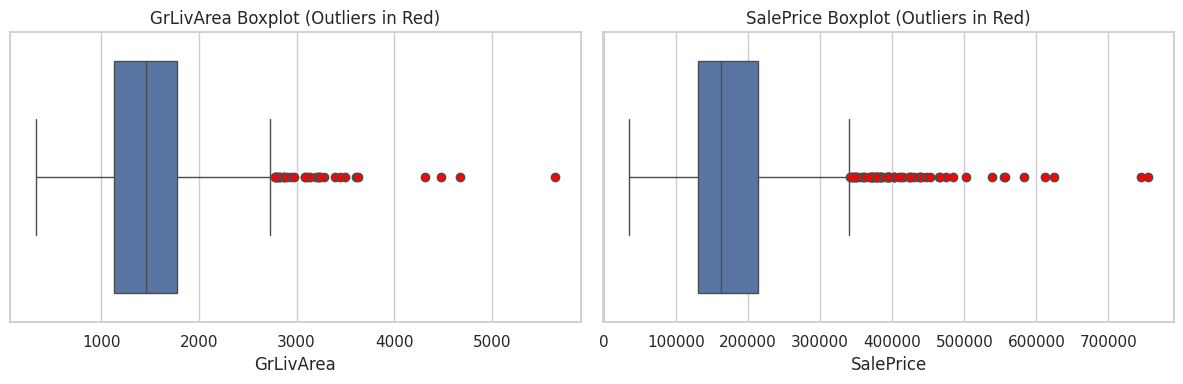

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["GrLivArea"], ax=axes[0], flierprops={"markerfacecolor": "red", "marker": "o"})
axes[0].set_title("GrLivArea Boxplot (Outliers in Red)")
sns.boxplot(x=df["SalePrice"], ax=axes[1], flierprops={"markerfacecolor": "red", "marker": "o"})
axes[1].set_title("SalePrice Boxplot (Outliers in Red)")
plt.tight_layout()
plt.show()

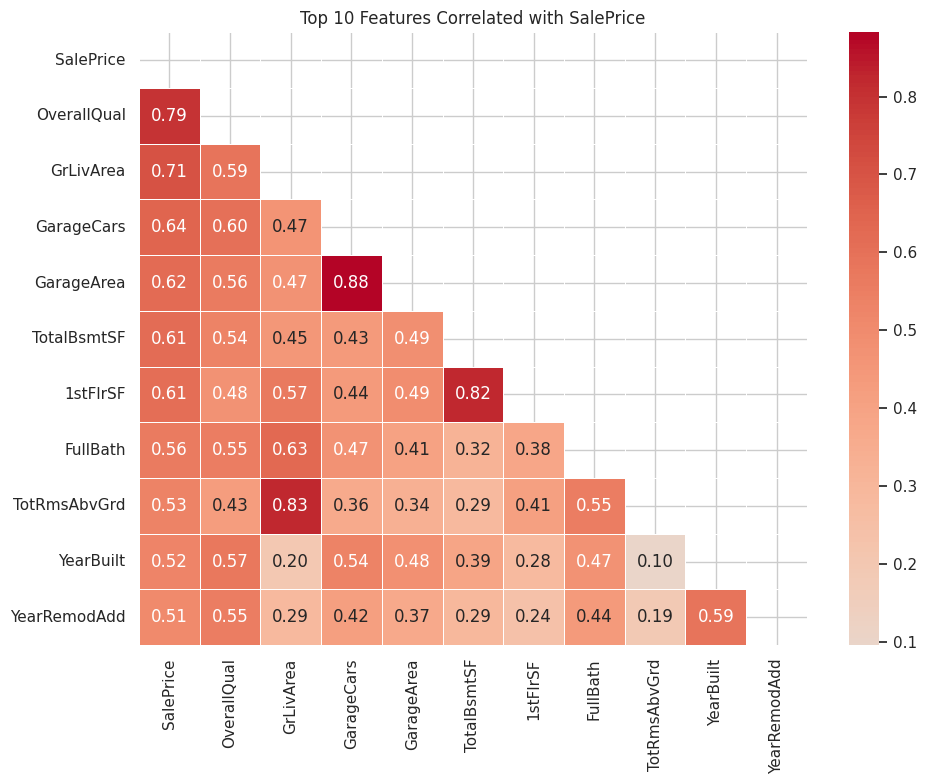

In [36]:
top10_cols = corr_matrix["SalePrice"].abs().sort_values(ascending=False).index[:11]
corr_top = df[top10_cols].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Top 10 Features Correlated with SalePrice")
plt.tight_layout()
plt.show()

GrLivArea -> IQR count: 31, Z-score count: 16, Overlap: 16
SalePrice -> IQR count: 61, Z-score count: 22, Overlap: 22


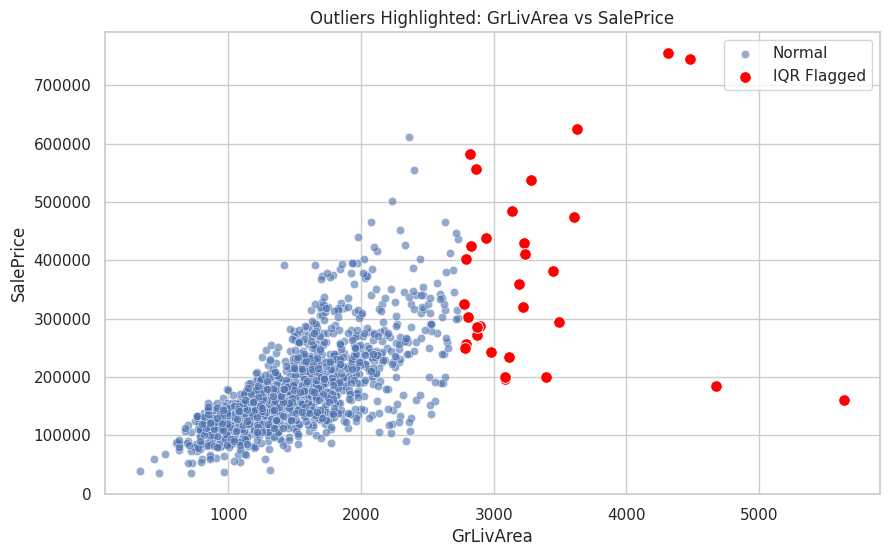

Original rows: 1460 | Cleaned rows: 1458


In [37]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)].index

def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return series[z.abs() > threshold].index

for col in ["GrLivArea", "SalePrice"]:
    a = set(iqr_outliers(df[col]))
    b = set(zscore_outliers(df[col]))
    print(f"{col} -> IQR count: {len(a)}, Z-score count: {len(b)}, Overlap: {len(a & b)}")

flagged_idx = iqr_outliers(df["GrLivArea"])
plt.figure(figsize=(10, 6))
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df, label="Normal", alpha=0.6)
sns.scatterplot(x=df.loc[flagged_idx, "GrLivArea"], y=df.loc[flagged_idx, "SalePrice"], color="red", label="IQR Flagged", s=70)
plt.title("Outliers Highlighted: GrLivArea vs SalePrice")
plt.legend()
plt.show()

df_clean = df[~((df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000))].copy()
print("Original rows:", len(df), "| Cleaned rows:", len(df_clean))

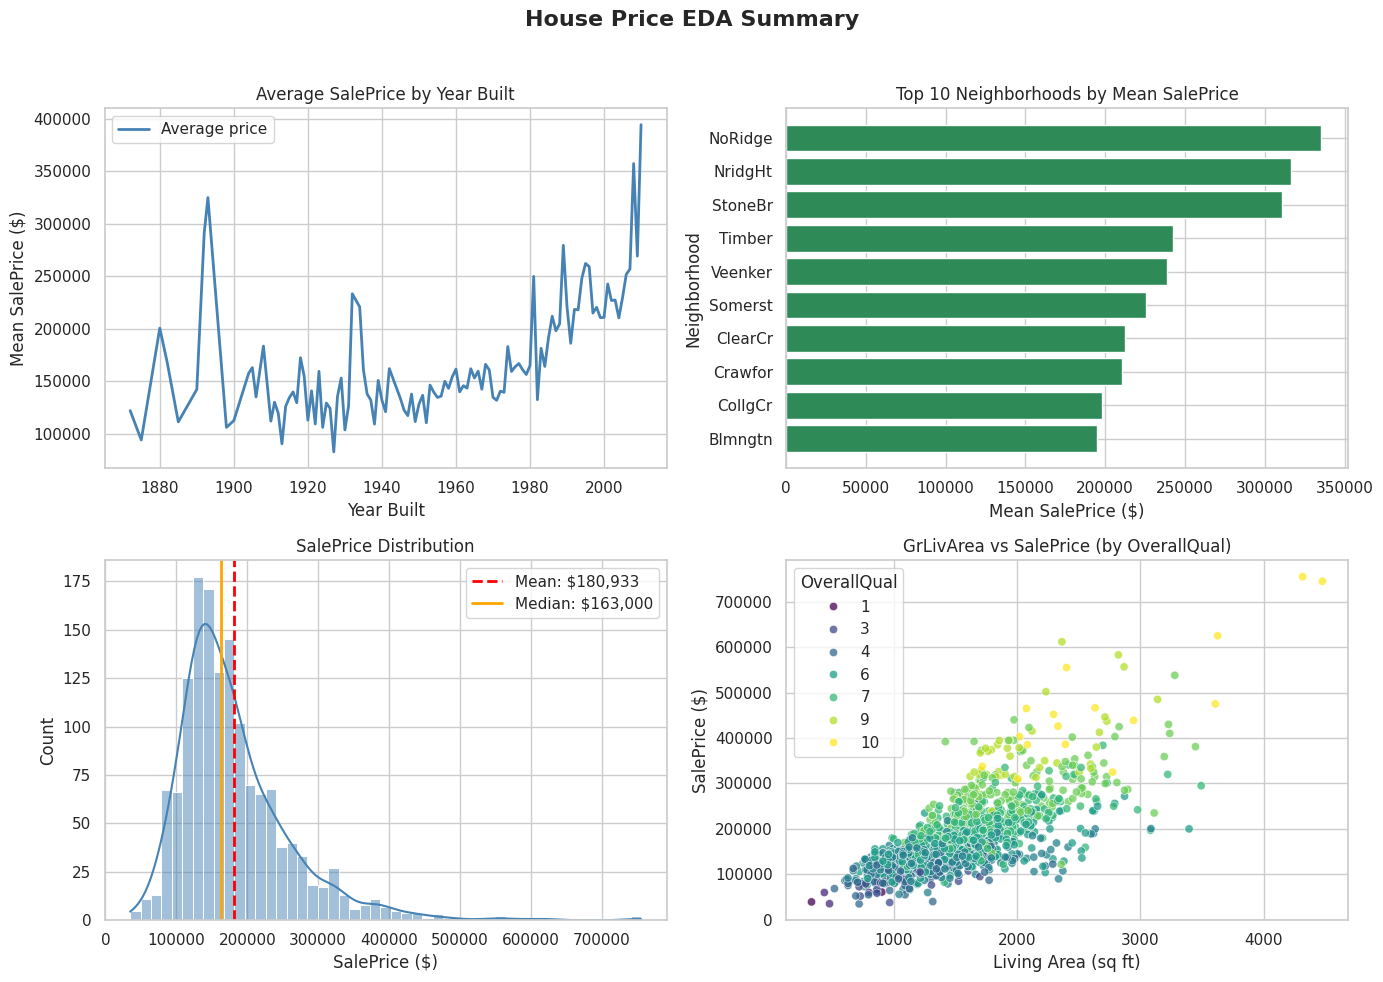

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

yr_mean = df_clean.groupby("YearBuilt")["SalePrice"].mean()
axes[0, 0].plot(yr_mean.index, yr_mean.values, color="steelblue", linewidth=2, label="Average price")
axes[0, 0].set_title("Average SalePrice by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Mean SalePrice ($)")
axes[0, 0].legend()

top10_nb = df_clean.groupby("Neighborhood")["SalePrice"].mean().sort_values(ascending=True).tail(10)
axes[0, 1].barh(top10_nb.index, top10_nb.values, color="seagreen")
axes[0, 1].set_title("Top 10 Neighborhoods by Mean SalePrice")
axes[0, 1].set_xlabel("Mean SalePrice ($)")
axes[0, 1].set_ylabel("Neighborhood")

sns.histplot(df_clean["SalePrice"], kde=True, ax=axes[1, 0], color="steelblue")
mean_p = df_clean["SalePrice"].mean()
med_p = df_clean["SalePrice"].median()
axes[1, 0].axvline(mean_p, color="red", linestyle="--", linewidth=2, label=f"Mean: ${mean_p:,.0f}")
axes[1, 0].axvline(med_p, color="orange", linestyle="-", linewidth=2, label=f"Median: ${med_p:,.0f}")
axes[1, 0].set_title("SalePrice Distribution")
axes[1, 0].set_xlabel("SalePrice ($)")
axes[1, 0].legend()

sns.scatterplot(
    x="GrLivArea", y="SalePrice", hue="OverallQual",
    palette="viridis", data=df_clean, ax=axes[1, 1], alpha=0.75
)
axes[1, 1].set_title("GrLivArea vs SalePrice (by OverallQual)")
axes[1, 1].set_xlabel("Living Area (sq ft)")
axes[1, 1].set_ylabel("SalePrice ($)")

fig.suptitle("House Price EDA Summary", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("eda_dashboard.png", dpi=150)
plt.show()